1. Importação das bibliotecas

In [3]:
# manipulação de dados
import numpy as np
import matplotlib.pyplot as plt
from scipy.io.wavfile import write

# análise e captura de áudio
import parselmouth
from fastdtw import fastdtw
import sounddevice as sd
from IPython.display import Audio

# reconhecimento e comparação com chinês
import edge_tts
import pypinyin
from vosk import Model, KaldiRecognizer

# módulos de formato de arquivos
import wave
import json

# modelo básico chinês do vosk
model_vosk = Model("./model/vosk-model-cn-0.22")

2. Bloco de funções para captura e tratamento de dados do usuário

In [4]:
# remove silêncio no início e fim do áudio
def trim_audio_data(audio_data, threshold=0.01):
    # threshold = sensibilidade para ruídos

    # verifica se valores positivos do áudio são maiores que o limite de ruídos
    mask = np.abs(audio_data) > threshold
    if not np.any(mask):
        return audio_data # retorna original se só tiver silencio

    # início e fim da gravação válida
    start_idx = np.argmax(mask)
    end_idx = len(mask) - np.argmax(mask[::-1])

    return audio_data[start_idx:end_idx]

# gravação de áudio do usuário
def audio_recording(filename='user_audio.wav', duration=2, sample_rate=16000):
    print('>>> Fale a sílaba...')

    audio_raw = sd.rec(int(duration * sample_rate), samplerate=sample_rate, channels=1, dtype='float32')
    sd.wait() # espera finalizar gravação
    print('Gravação finalizada.')

    audio_trimmed = trim_audio_data(audio_raw.flatten()) # audio unidirecional

    # transforma em int16 usado em arquivos .wav
    audio_int16 = (audio_trimmed * 32767).astype(np.int16)

    write(filename, sample_rate, audio_int16)
    print(f">>> Tamanho original: {len(audio_raw)} | Após limpeza: {len(audio_trimmed)}")
    return filename

# verifica se áudio contém sílaba a comparar
def verify_content(audio_path, expected_pinyin):
    wf = wave.open(audio_path, "rb")
    rec = KaldiRecognizer(model_vosk, wf.getframerate())
    data = wf.readframes(wf.getnframes())
    rec.AcceptWaveform(data)

    result = json.loads(rec.FinalResult())
    transcribed_text = result.get("text", "").replace(" ", "")

    # pinyin de exibilição (com tom)
    py_display = pypinyin.pinyin(transcribed_text, style=pypinyin.Style.TONE3)
    pinyin_with_tone = "".join([p[0] for p in py_display])

    # pinyin de comparação (sem tom)
    py_clean = pypinyin.pinyin(transcribed_text, style=pypinyin.Style.NORMAL)
    pinyin_without_tone = "".join([p[0] for p in py_clean]).lower()

    # limpeza do pinyin de referência (apenas texto)
    pinyin_ref = "".join([c for c in expected_pinyin if c.isalpha()]).lower()

    # verifica apenas paridade (?) da sílaba e não do tom
    is_correct = pinyin_with_tone == pinyin_ref

    return is_correct, pinyin_without_tone, transcribed_text

In [ ]:
# Bloco para iniciar captura do áudio:
audio_recording('user_audio.wav')

display(Audio(data='user_audio.wav', rate=16000))

>>> Fale a sílaba...
Gravação finalizada!
✅ Gravação limpa e salva! Tamanho original: 88200 | Novo: 86877


3. Função de leitura e tratamento do áudio com Librosa

In [ ]:
# extrai a frequência (altura) do som
def extract_pitch_data(file_path):
    audio = parselmouth.Sound(file_path)
    pitch = audio.to_pitch(pitch_floor=75, pitch_ceiling=600)
    return pitch

# trata array de frequência para remover silêncio
def get_clean_frequencies(pitch_objetct):
    freqs = pitch_objetct.selected_array['frequency']
    freqs[freqs == 0] = np.nan # remove silencio para visualização
    return freqs

#  limpeza para algoritmo de comparação
def prepare_for_dtw(series):
    # remove NaNs
    clean_series = series[~np.isnan(series)]

    if len(clean_series) == 0:
        return np.array([])

    # normalização Z-Score
    normalized = (clean_series - np.mean(clean_series)) / np.std(clean_series)

    return normalized.reshape(-1, 1)

# função completa de processamento
def process_audio(file_path):
    pitch_raw = extract_pitch_data("ref_audio.wav")
    clean_freqs = get_clean_frequencies(pitch_raw)
    dtw_ready_data = prepare_for_dtw(clean_freqs)

    return dtw_ready_data

In [ ]:
# tratamento completo dos dois arquivos de áudio
final_ref_audio = process_audio("ref_audio.wav")
final_user_audio = process_audio("user_audio.wav")

if final_ref_audio.size == 0 or final_user_audio.size == 0:
    print(">>> Erro: Não foi possível detectar voz em um dos áudios.")
    print(f"Tamanho referência: {final_ref_audio.size}, Tamanho usuário: {final_user_audio.size}")
    distance = np.array([np.inf])
    path = []
else:
    # cálculo do DTW
    distance, path = fastdtw(final_ref_audio, final_user_audio, dist=lambda x, y: np.abs(x - y))

    print(f"Formato referência: {final_ref_audio.shape}, Formato usuário: {final_user_audio.shape}")
    print(f"Distância DTW: {distance.item():.2f}")

Ref shape: (13, 1), User shape: (33, 1)
Distância DTW: 18.73


4. Feedback de tom e fonética

In [ ]:
# entradas
target_pinyin = "xie1"
audio_file = "user_audio.wav"

# validação de pitch
avg_distance = distance.item() / len(path)
print(f">>> Distância Média por Frame: {avg_distance:.4f}")

# parâmetros de similaridade (melhorar isso aqui)
limit = 0.5  
tone_ok = avg_distance < limit

# validação do fonema
is_correct, spoken_pinyin, hanzi = verify_content(audio_file, target_pinyin)
# add depois hanzi fixo (flashcard)

# resultado
print(">>> RESULTADO DA PRONÚNCIA")
if is_correct and tone_ok:
    print(f"Perfeito! '{hanzi}' ({spoken_pinyin}) com o tom correto.")
elif is_correct and not tone_ok:
    print(f"Som correto ({spoken_pinyin}), mas o TOM está errado.")
elif not is_correct and tone_ok:
    print(f"Tom correto, mas o fonema saiu como '{spoken_pinyin}' ao invés de '{target_pinyin}'")
else:
    print(f"Som e fonema incorretos. Falado '{hanzi}' '{spoken_pinyin}' ao invés de '{target_pinyin}'?")

Distância Média por Frame: 0.5774
--- RESULTADO DA PRONÚNCIA ---
❌ Ops! Tanto o som quanto o tom parecem incorretos. Você disse '解' 'jie'. Você quis dizer 'xie1'?


5. Visualização da curva no gráfico

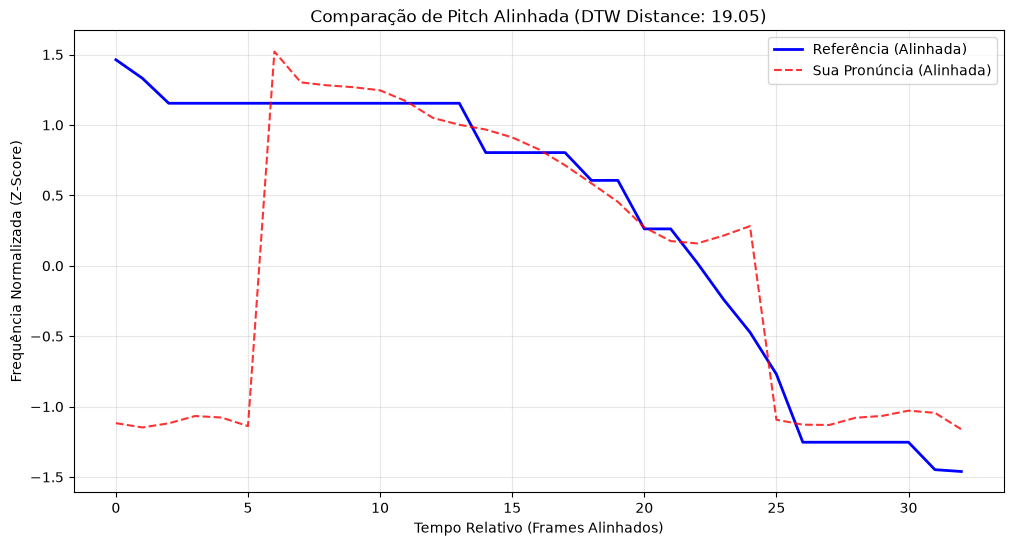

In [ ]:
plt.figure(figsize=(12, 6))

# arrays para armazenar os valores alinhados
ref_aligned = []
user_aligned = []

# o 'path' contém pares de índices (i, j) onde i é ref e j é usuário
for i, j in path:
    ref_aligned.append(final_ref_audio[i])
    user_aligned.append(final_user_audio[j])

# plotagem
plt.plot(ref_aligned, label="Referência (Alinhada)", color='blue', linewidth=2)
plt.plot(user_aligned, label="Sua Pronúncia (Alinhada)", color='red', linestyle='--', alpha=0.8)

plt.title(f"Comparação de Pitch Alinhada (DTW Distance: {distance.item():.2f})")
plt.xlabel("Tempo Relativo (Frames Alinhados)")
plt.ylabel("Frequência Normalizada (Z-Score)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

X. Gerar áudio de referência

In [ ]:
async def generate_ref():
    TEXT = '谢'
    VOICE = 'zh-CN-YunxiNeural'
    communicate = edge_tts.Communicate(TEXT, VOICE)
    await communicate.save('ref_audio.wav')

await generate_ref()

display(Audio(data='ref_audio.wav', rate=16000))